# Class-weight benchmark and evaluation uncertainty

## Summary
Compare the saved balanced HGB with an unweighted HGB on identical features and partitions. Results below are exploratory; the earlier model is retained, with no new model selection on evaluation data. The chronological evaluation is the primary uncertainty analysis.

## Methods
The source date run selected its feature set on validation AP. This extension clones each saved estimator and changes only `class_weight=None`; it fits on the original training IDs. Scores and parameters of the saved model are verified against its manifest before comparison.

### Assumptions
Paired **time-bin cluster bootstrap**: group evaluation parts into nonoverlapping bins of earliest recorded time, sample occupied bins with replacement, and use the same multiplicities for both models. Recompute AP and the highest-risk 1% precision/recall in every draw. Use 1,000 draws, seed 42, percentile 95% intervals. Width 10 is the declared primary setting; widths 5 and 20 are sensitivity checks in dataset units, not days. Bin origin is the earliest evaluation timestamp; timestamp ties stay together. These widths are illustrative, not estimated dependence lengths.

This preserves dependence within bins but assumes bins are sufficiently independent and exchangeable. Dependence across bins, nonstationarity, feature selection, training variability, and previous test inspection are not corrected. No independent-holdout or future-performance claim follows. Score ties use stable original row order at capacity. Replicates with no defects have undefined recall/AP and are counted explicitly.

[HGB class-weight definition](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html). [Time-series bootstrap background](https://users.ssc.wisc.edu/~behansen/718/HardleHorowitzKreiss.pdf). This implementation uses fixed time-bin clusters with its assumptions stated above; the reference reviews time-series bootstrap methods.

In [1]:
import hashlib, json, os, platform
from datetime import datetime, timezone
from pathlib import Path
from importlib.metadata import version
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import average_precision_score
from threadpoolctl import threadpool_limits
from bosch import capacity_metrics
from bosch_dates import read_date_summary, read_numeric_counts, audit_join
from bosch_uncertainty import paired_time_bootstrap

ROOT = Path.cwd()
SOURCE = Path(os.environ.get('BOSCH_BENCHMARK_SOURCE', 'artifacts/dates_20261029T140103667151Z'))
manifest = json.loads((SOURCE / 'manifest.json').read_text())
assert manifest['requested_nrows'] is None, 'Requires a full date run.'
WIDTHS, REPLICATES, SEED = (5., 10., 20.), 1000, 42
RUN_ID = 'benchmark_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN = ROOT / 'artifacts' / RUN_ID
RUN.mkdir(parents=True)
for name, digest in manifest['code_sha256'].items():
    assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == digest, name
paths = {}
for name, variable in [('numeric', 'BOSCH_DATA_PATH'), ('dates', 'BOSCH_DATE_PATH')]:
    paths[name] = Path(os.environ.get(variable, manifest['sources'][name]['path']))
    stat = paths[name].stat()
    assert stat.st_size == manifest['sources'][name]['bytes']
    assert stat.st_mtime_ns == manifest['sources'][name]['mtime_ns']
print('Source run:', manifest['run_id'])
print('New run:', RUN_ID)
print('Declared bootstrap:', WIDTHS, REPLICATES, SEED)

Source run: dates_20261029T140103667151Z
New run: benchmark_20261030T212935628830Z
Declared bootstrap: (5.0, 10.0, 20.0) 1000 42


## Data and partition checks
Stream the full files and align saved split IDs exactly; source measurements and split membership are unchanged.

In [2]:
dates, _, _, date_schema = read_date_summary(paths['dates'])
numeric, numeric_schema = read_numeric_counts(paths['numeric'])
parts, audit, _, _ = audit_join(numeric, dates)
del numeric, dates
assert audit == manifest['join_audit']
assert list(numeric_schema) == manifest['numeric_schema']
assert list(date_schema) == manifest['date_schema']
index = pd.Index(parts['Id'])
saved_ids = np.load(SOURCE / 'split_ids.npz')
splits = {key: index.get_indexer(saved_ids[key]) for key in saved_ids.files}
assert all((rows >= 0).all() for rows in splits.values())
for strategy in ['random_same_cohort', 'chronological_purged']:
    groups = [splits[f'{strategy}__{name}'] for name in ['train', 'validation', 'exploratory_evaluation']]
    assert len(np.unique(np.concatenate(groups))) == sum(map(len, groups))
print('Full joined parts:', len(parts))
print('Saved split IDs matched and disjoint within each strategy.')

Full joined parts: 1183747
Saved split IDs matched and disjoint within each strategy.


## Benchmark results
The saved balanced model is scored again and must reproduce recorded AP and capacity counts. The unweighted comparator receives no tuning or evaluation-driven feature selection.

In [3]:
rows, predictions, parameters = [], {}, {}
for strategy in ['random_same_cohort', 'chronological_purged']:
    bundle = joblib.load(SOURCE / f'{strategy}_model.joblib')  # trusted local artifact
    model, columns = bundle['estimator'], bundle['columns']
    assert all(model.get_params()[k] == v for k, v in manifest['model_parameters'].items())
    train = splits[f'{strategy}__train']
    evaluation = splits[f'{strategy}__exploratory_evaluation']
    x = parts.loc[:, columns]
    y = parts.Response.to_numpy()
    benchmark = clone(model).set_params(class_weight=None)
    with threadpool_limits(limits=4):
        benchmark.fit(x.iloc[train], y[train])
        scores = {'balanced': model.predict_proba(x.iloc[evaluation])[:, 1],
                  'unweighted': benchmark.predict_proba(x.iloc[evaluation])[:, 1]}
    original = next(r for r in manifest['exploratory_evaluation_results'] if r['strategy'] == strategy)
    for name, values in scores.items():
        ap = float(average_precision_score(y[evaluation], values))
        cap = capacity_metrics(y[evaluation], values)
        if name == 'balanced':
            assert np.isclose(ap, original['average_precision'], rtol=0, atol=1e-12)
            assert cap['tp'] == original['tp'] and cap['inspected'] == original['inspected']
        rows.append(dict(strategy=strategy, model=name, parts=len(evaluation),
                         defects=int(y[evaluation].sum()), average_precision=ap, **cap))
    predictions[strategy] = scores
    parameters[strategy] = {'columns': list(columns), 'balanced': model.get_params(),
                            'unweighted': benchmark.get_params()}
    joblib.dump(benchmark, RUN / f'{strategy}_unweighted.joblib')
    np.savez_compressed(RUN / f'{strategy}_predictions.npz',
                        ids=parts.Id.iloc[evaluation].to_numpy(), labels=y[evaluation],
                        times=parts.date_first.iloc[evaluation].to_numpy(), **scores)
results = pd.DataFrame(rows)
display(results[['strategy', 'model', 'average_precision', 'precision', 'recall', 'tp', 'inspected']])
results.to_csv(RUN / 'benchmark_results.csv', index=False)

,strategy,model,average_precision,precision,recall,tp,inspected
0,random_same_cohort,balanced,0.066006,0.105354,0.178886,244,2316
1,random_same_cohort,unweighted,0.066781,0.110535,0.187683,256,2316
2,chronological_purged,balanced,0.016582,0.047740,0.117220,113,2367
3,chronological_purged,unweighted,0.011853,0.041403,0.101660,98,2367


## Inspection capacity and recall

Keep the original balanced chronological model fixed. Report 1%, 2%, 5%, and 10% inspection capacity for validation and exploratory evaluation separately. Capacity means inspecting ceil(n × fraction) highest-ranked parts, not a fixed probability threshold. Validation is the place to develop an operating policy; evaluation rows are a retrospective diagnostic, not a basis for choosing a new capacity. No factory budget or target recall is assumed.

Increasing capacity necessarily expands the inspected set and cannot decrease the number of defects found. Precision can fall or rise. This is a workload trade-off, not evidence of a better model. The intervals below remain specific to the original 1% operating point.

In [4]:
capacity_rows = []
strategy = 'chronological_purged'
bundle = joblib.load(SOURCE / f'{strategy}_model.joblib')
for partition in ['validation', 'exploratory_evaluation']:
    subset = splits[f'{strategy}__{partition}']
    if partition == 'validation':
        with threadpool_limits(limits=4):
            scores = bundle['estimator'].predict_proba(parts.loc[:, bundle['columns']].iloc[subset])[:, 1]
    else:
        scores = predictions[strategy]['balanced']
    for capacity in [.01, .02, .05, .10]:
        capacity_rows.append(dict(partition=partition, parts=len(subset),
                                  defects=int(parts.Response.iloc[subset].sum()),
                                  **capacity_metrics(parts.Response.iloc[subset], scores, capacity)))
capacity_results = pd.DataFrame(capacity_rows)
display(capacity_results[['partition', 'capacity_requested', 'inspected', 'tp', 'fp', 'fn', 'precision', 'recall']])
capacity_results.to_csv(RUN / 'capacity_results.csv', index=False)

,partition,capacity_requested,inspected,tp,fp,fn,precision,recall
0,validation,0.01,1869,112,1757,462,0.059925,0.195122
1,validation,0.02,3737,116,3621,458,0.031041,0.202091
2,validation,0.05,9342,127,9215,447,0.013595,0.221254
3,validation,0.10,18684,157,18527,417,0.008403,0.273519
4,exploratory_evaluation,0.01,2367,113,2254,851,0.047740,0.117220
5,exploratory_evaluation,0.02,4733,122,4611,842,0.025776,0.126556
6,exploratory_evaluation,0.05,11832,157,11675,807,0.013269,0.162863
7,exploratory_evaluation,0.10,23664,211,23453,753,0.008916,0.218880


## Chronological uncertainty
Resample the same time bins for both models. Paired differences are balanced minus unweighted; intervals crossing zero do not establish a directional advantage under these assumptions. These are marginal intervals, without a multiple-comparison correction.

In [5]:
evaluation = splits['chronological_purged__exploratory_evaluation']
intervals, diagnostics, draws = paired_time_bootstrap(
    parts.Response.iloc[evaluation].to_numpy(), predictions['chronological_purged'],
    parts.date_first.iloc[evaluation].to_numpy(), widths=WIDTHS,
    replicates=REPLICATES, seed=SEED)
display(diagnostics)
display(intervals[intervals.width == 10.])
intervals.to_csv(RUN / 'bootstrap_intervals.csv', index=False)
np.savez_compressed(RUN / 'bootstrap_draws.npz', **draws)
print('Intervals are conditional on the fitted models and this evaluation period.')

,width,occupied_bins,min_parts,max_parts,valid_replicates,omitted_replicates
0,5.0,69,1,12953,1000,0
1,10.0,36,594,16099,1000,0
2,20.0,18,3362,27404,1000,0


,width,model,metric,estimate,lower,upper
9,10.0,balanced,average_precision,0.016582,0.010947,0.026077
10,10.0,balanced,precision_at_capacity,0.047740,0.033665,0.064349
11,10.0,balanced,recall_at_capacity,0.117220,0.085784,0.153019
12,10.0,unweighted,average_precision,0.011853,0.007553,0.022105
13,10.0,unweighted,precision_at_capacity,0.041403,0.026415,0.059006
14,10.0,unweighted,recall_at_capacity,0.101660,0.068844,0.142857
15,10.0,balanced_minus_unweighted,average_precision,0.004729,-0.000794,0.009823
16,10.0,balanced_minus_unweighted,precision_at_capacity,0.006337,-0.002532,0.015556
17,10.0,balanced_minus_unweighted,recall_at_capacity,0.015560,-0.006217,0.037662


Intervals are conditional on the fitted models and this evaluation period.


### Primary intervals and block-width sensitivity
Dots show observed estimates; lines show percentile 95% intervals. The second table reports paired differences at every declared width, so the width choice is visible.

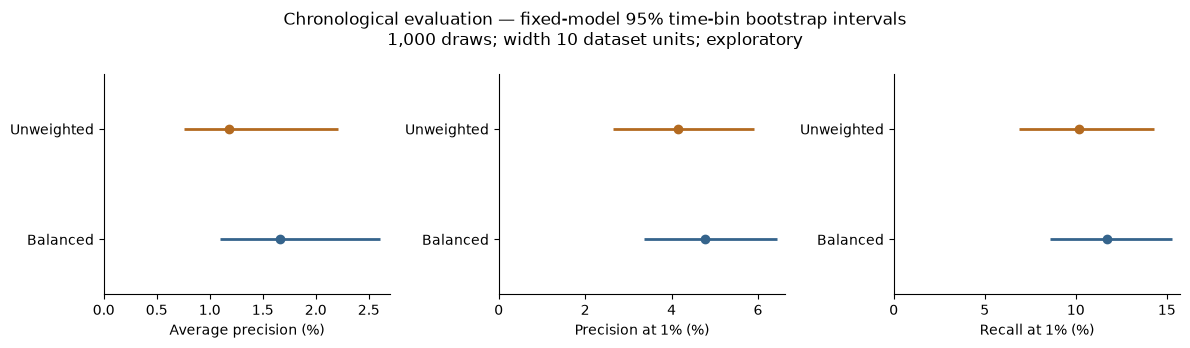

,width,model,metric,estimate,lower,upper
6,5.0,balanced_minus_unweighted,average_precision,0.004729,-0.000438,0.010110
7,5.0,balanced_minus_unweighted,precision_at_capacity,0.006337,-0.001884,0.015455
8,5.0,balanced_minus_unweighted,recall_at_capacity,0.015560,-0.004778,0.037470
15,10.0,balanced_minus_unweighted,average_precision,0.004729,-0.000794,0.009823
16,10.0,balanced_minus_unweighted,precision_at_capacity,0.006337,-0.002532,0.015556
17,10.0,balanced_minus_unweighted,recall_at_capacity,0.015560,-0.006217,0.037662
24,20.0,balanced_minus_unweighted,average_precision,0.004729,-0.001961,0.011249
25,20.0,balanced_minus_unweighted,precision_at_capacity,0.006337,-0.003071,0.017835
26,20.0,balanced_minus_unweighted,recall_at_capacity,0.015560,-0.007467,0.045442


In [6]:
primary = intervals[(intervals.width == 10) & (intervals.model != 'balanced_minus_unweighted')]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, metric, label in zip(axes, ['average_precision', 'precision_at_capacity', 'recall_at_capacity'],
                            ['Average precision (%)', 'Precision at 1% (%)', 'Recall at 1% (%)']):
    for i, (name, color) in enumerate([('balanced', '#35648c'), ('unweighted', '#b36a20')]):
        r = primary[(primary.model == name) & (primary.metric == metric)].iloc[0]
        ax.hlines(i, r.lower * 100, r.upper * 100, color=color, linewidth=2)
        ax.plot(r.estimate * 100, i, 'o', color=color)
    ax.set(yticks=[0, 1], yticklabels=['Balanced', 'Unweighted'], xlabel=label, ylim=(-.5, 1.5))
    ax.set_xlim(left=0)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Chronological evaluation — fixed-model 95% time-bin bootstrap intervals\n1,000 draws; width 10 dataset units; exploratory')
fig.tight_layout()
fig.savefig(RUN / 'benchmark_uncertainty.png', dpi=150, bbox_inches='tight')
plt.show()
display(intervals[intervals.model == 'balanced_minus_unweighted'])

## Takeaways
Balanced HGB achieved 1.66% chronological AP versus 1.19% for unweighted HGB. Paired 95% intervals include zero at all tested widths, so this analysis does not establish a class-weighting advantage. Increasing inspection capacity changes workload and defect coverage, not the model ranking; use the validation table and an actual operational budget before choosing a policy.

The intervals describe fixed-model evaluation sampling under the stated time-bin assumptions. Prior exploration, unknown prediction-time feature availability, and future drift remain unresolved. No replacement model or new operating capacity is selected here.

In [7]:
receipt = {
    'run_id': RUN_ID, 'source_run_id': manifest['run_id'], 'scope': 'full files; saved date partitions',
    'source_manifest_sha256': hashlib.sha256((SOURCE / 'manifest.json').read_bytes()).hexdigest(),
    'split_ids_sha256': hashlib.sha256((SOURCE / 'split_ids.npz').read_bytes()).hexdigest(),
    'code_sha256': {name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest()
                    for name in ['bosch.py', 'bosch_dates.py', 'bosch_uncertainty.py', 'requirements.lock']},
    'notebook_source_sha256': hashlib.sha256(json.dumps([
        {'cell_type': c['cell_type'], 'source': ''.join(c['source'])}
        for c in json.loads((ROOT / 'benchmark_analysis.ipynb').read_text())['cells']
    ], sort_keys=True).encode()).hexdigest(),
    'python': platform.python_version(),
    'versions': {name: version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'matplotlib']},
    'capacity_results': capacity_results.to_dict(orient='records'),
    'parameters': parameters, 'benchmark_results': results.to_dict(orient='records'),
    'bootstrap': {'method': 'paired nonoverlapping occupied time-bin cluster percentile',
                  'widths': WIDTHS, 'primary_width': 10., 'replicates': REPLICATES, 'seed': SEED,
                  'coverage': .95, 'capacity': .01, 'scope': 'chronological evaluation only',
                  'diagnostics': diagnostics.to_dict(orient='records'),
                  'intervals': intervals.to_dict(orient='records')},
    'independent_holdout': False, 'includes_training_uncertainty': False,
    'operational_feature_availability_verified': False,
}
(RUN / 'manifest.json').write_text(json.dumps(receipt, indent=2) + '\n')
print('Saved aggregate receipt and local predictions:', RUN.relative_to(ROOT))

Saved aggregate receipt and local predictions: artifacts/benchmark_20261030T212935628830Z
